# Phase 1 â€” Data (warm-up): Coca-Cola and PepsiCo over 46 years

**What the brief asks.** Download the daily price history of the pair, plot the two prices together,
plot their ratio or difference over time, look at the correlation of their daily returns, and get a
feel for whether the relationship looks stable or visibly drifts over the decades.

**What this notebook does.** It uses the whole history that Yahoo Finance has for both stocks, from
1 June 1972 to 31 December 2018 (46 years). It shows what the raw data looks like, reports every stock
split and dividend, explains how the data was checked and cleaned, draws the three charts of the brief,
reads them decade by decade, and explains why the strategy of the next phases is estimated on
2000â€“2018 only.

**Why this pair.** Coca-Cola (ticker **KO**) and PepsiCo (ticker **PEP**) sell very similar products
to the same customers, so their shares react to much of the same news (consumer spending, sugar and
aluminium costs, the dollar). Pairs trading bets on exactly this: when two related prices drift apart
for a while, they tend to come back together. Before building any strategy we check how strong and how
stable this link has been.

**Words used below**

| Term | Meaning |
|---|---|
| Close price | The last traded price of the day (Yahoo already corrects it for stock splits) |
| Stock split | The company swaps each share for two or three: the price drops in proportion, the value held does not change |
| Dividend | Cash paid by the company to shareholders, here every quarter; on the *ex-date* the price drops by about that amount |
| Spin-off | The company gives its shareholders the shares of a business it separates from itself |
| Adjusted close price | The close price also corrected for dividends (and spin-offs), so that a payment does not look like a price drop |
| Daily return | The percentage change of the price from one trading day to the next |
| Correlation | A number between -1 and +1: +1 means the two daily returns always move together, 0 means no relation |
| Log scale | A vertical axis where equal distances mean equal *percentage* changes (100 to 200 looks as tall as 1,000 to 2,000) |
| In-sample / out-of-sample | The past the strategy is studied and tuned on (2000â€“2018) / the later period (2019â€“2026), kept untouched for the final, one-off test |

## 1. Set-up

**Period described here: 1 June 1972 â€“ 31 December 2018.** 1 June 1972 is PepsiCo's first day on
Yahoo (Coca-Cola starts in 1962; those earlier days have no PepsiCo price to compare with and are not
used). The constant `HISTORY_START` in `src/pairs/config.py` holds this date.

**Why the charts stop at 2018.** The years 2019â€“2026 are the out-of-sample period: the final exam of
the strategy, run once at the end of the project. The brief asks not to look at that period until we
are done. It does not require the split for this descriptive phase, but a chart of 2019â€“2026 seen now
could still influence the choices of Phases 2 and 3, so we leave it out. After the single
out-of-sample run, the same charts are shown on 1972â€“2026.

**Two periods, two roles.** 1972â€“2018 is *described* here. 2000â€“2018 is the *in-sample* period, the
only one on which the strategy of the next phases is estimated and tuned. That split was fixed in the
code before any price was downloaded; section 7 explains why it starts in 2000.

In [1]:
from itertools import pairwise

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from pairs.config import HISTORY_START, PAIR, Settings
from pairs.data import (
    KNOWN_DIVIDEND_ERRORS,
    VALIDATED_FILE,
    correct_dividend_errors,
    fetch_context_prices,
    fetch_corporate_actions,
    fetch_raw_prices,
)
from pairs.explore import (
    adjustment_from_dividends,
    daily_returns,
    largest_moves,
    longest_gaps,
    select_until,
    yearly_correlation,
)
from pairs.logging_setup import configure_logging
from pairs.plots import finish_figure, save_figure

configure_logging()
# Interactive chart in VS Code / Jupyter, plus a static PNG copy that GitHub can display
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
SOURCE = "Source: Yahoo Finance, 1 Jun 1972 - 31 Dec 2018."
SHADED = " Shaded: 2000-2018, the in-sample period of the strategy."
COLORS = {"KO": "#c0392b", "PEP": "#1f4e9c"}
NAMES = {"KO": "Coca-Cola (KO)", "PEP": "PepsiCo (PEP)"}
start = pd.Timestamp(HISTORY_START)

pd.DataFrame(
    [
        ("Pair", "KO (Coca-Cola) and PEP (PepsiCo)", "Textbook pair: same sector"),
        ("Period described here", f"{HISTORY_START} to {PAIR.in_sample_end}", "All common history"),
        ("Strategy in-sample", f"{PAIR.start} to {PAIR.in_sample_end}", "Reasons: section 7"),
        ("Out-of-sample (run once)", f"after {PAIR.in_sample_end} to {PAIR.end}", "Not used here"),
        ("Price used", "Adjusted close", "A dividend would look like a price drop"),
        ("Returns", "Simple daily returns", "The intuitive percentage change"),
        ("Missing days", "Dropped, never filled", "Filling would invent a zero return"),
    ],
    columns=["Item", "Choice", "Why"],
).set_index("Item")

,Choice,Why
Item,,
Pair,KO (Coca-Cola) and PEP (PepsiCo),Textbook pair: same sector
Period described here,1972-06-01 to 2018-12-31,All common history
Strategy in-sample,2000-01-03 to 2018-12-31,Reasons: section 7
Out-of-sample (run once),after 2018-12-31 to 2026-10-09,Not used here
Price used,Adjusted close,A dividend would look like a price drop
Returns,Simple daily returns,The intuitive percentage change
Missing days,"Dropped, never filled",Filling would invent a zero return


## 2. What the raw data looks like

The prices come in two downloads, each saved once exactly as Yahoo sends it, so that every number can
be reproduced (Yahoo rewrites its adjusted prices after every new dividend): `data/prices_context_raw.pkl`
(up to 1999) and `data/prices_raw.pkl` (from 2000). For each stock and day they hold six columns: open,
high, low, close, adjusted close and volume (number of shares traded). Joined, the first rows are:

In [2]:
context_raw = fetch_context_prices(PAIR, settings.data_dir)
ko_only = context_raw.loc[context_raw.index < start]
main_raw = select_until(fetch_raw_prices(PAIR, settings.data_dir), PAIR.in_sample_end)
raw = pd.concat([context_raw.loc[context_raw.index >= start], main_raw])
display(raw[["Close", "Adj Close", "Volume"]].head().round(3))
pd.Series(
    {
        "Trading days with both stocks": len(raw),
        "First day": raw.index[0].date(),
        "Last day": raw.index[-1].date(),
        "KO-only days before 1 Jun 1972 (not used)": len(ko_only),
    }
).to_frame("value")

12:13:43 INFO     Loading context checkpoint C:\Users\gianl\Documents\bsq-pairs-trading\data\prices_context_raw.pkl

         INFO     Loading raw checkpoint C:\Users\gianl\Documents\bsq-pairs-trading\data\prices_raw.pkl

         INFO     Kept 4779 of 6733 rows up to 2018-12-31

Price       Close        Adj Close          Volume          
Ticker         KO    PEP        KO    PEP       KO       PEP
Date                                                        
1972-06-01  1.378  1.602     0.286  0.367   748800  318600.0
1972-06-02  1.372  1.597     0.284  0.366   393600  140400.0
1972-06-05  1.370  1.574     0.284  0.361   662400  469800.0
1972-06-06  1.358  1.560     0.281  0.358   768000  140400.0
1972-06-07  1.352  1.551     0.280  0.356  1420800  178200.0

,value
Trading days with both stocks,11749
First day,1972-06-01
Last day,2018-12-31
KO-only days before 1 Jun 1972 (not used),2599


The prices of 1972 look tiny (KO 1.38 dollars) because Yahoo rewrites them for every split that came
later; section 3.1 converts them back to the prices people actually paid.

## 3. Stock splits and dividends

Splits and dividends change how past prices must be read, so every one of them in the period is
reported here (source: Yahoo Finance, saved in `data/actions_raw.pkl`).

### 3.1 Stock splits: ten since 1972

For each split the table shows two checks. If Yahoo had *not* corrected the earlier prices, the close
would show a fake drop on the split day: -50% for a 2-for-1 split, -67% for a 3-for-1. And the traded
volume (also corrected by Yahoo) would jump two or three times.

In [3]:
events = fetch_corporate_actions(PAIR, settings.data_dir)
events = select_until(events.loc[events.index >= start], PAIR.in_sample_end)
close = raw["Close"][["KO", "PEP"]]
volume = raw["Volume"][["KO", "PEP"]]
split_rows = []
for day, event in events.loc[events["split"] > 0].iterrows():
    ticker = event["ticker"]
    before = volume[ticker].loc[day - pd.Timedelta(days=91) : day - pd.Timedelta(days=1)]
    after = volume[ticker].loc[day : day + pd.Timedelta(days=91)]
    split_rows.append(
        {
            "date": day,
            "ticker": ticker,
            "new shares per old share": event["split"],
            "close return that day (%)": 100 * close[ticker].pct_change().loc[day],
            "median volume, 3 months after / before": after.median() / before.median(),
        }
    )
splits = pd.DataFrame(split_rows).set_index("date")
splits.round(2)

         INFO     Loading corporate actions checkpoint                                                             
                  C:\Users\gianl\Documents\bsq-pairs-trading\data\actions_raw.pkl

         INFO     Kept 386 of 448 rows up to 2018-12-31

,ticker,new shares per old share,close return that day (%),"median volume, 3 months after / before"
date,,,,
1977-05-31,PEP,3.0,-2.35,0.98
1977-06-01,KO,2.0,3.65,0.46
1986-05-29,PEP,3.0,7.63,0.77
1986-07-01,KO,3.0,2.19,0.79
1990-05-14,KO,2.0,0.90,0.85
1990-09-05,PEP,3.0,1.68,0.80
1992-05-12,KO,2.0,0.44,0.79
1996-05-13,KO,2.0,2.53,0.86
1996-05-29,PEP,2.0,0.19,0.96


**All ten splits are correctly handled.** On the split days the close moves between -2.4% and
+7.6%, far from -50% or -67%, and the volume does not jump (after / before between 0.5 and 1.0). The
largest one-day move of either stock in 46 years is -24.7% (Black Monday, section 4), so no split is
hidden anywhere else in the data.

**What a 1972 price really was.** Every split after a day divides the price Yahoo shows for that day.
Since June 1972 one KO share has become 96 shares (2 x 3 x 2 x 2 x 2 x 2) and one PEP share 54
(3 x 3 x 3 x 2). Multiplying back:

In [4]:
quoted = {}
for day in (start, pd.Timestamp(PAIR.start)):
    for ticker in ("KO", "PEP"):
        later = splits.loc[(splits["ticker"] == ticker) & (splits.index > day)]
        factor = float(later["new shares per old share"].prod())
        quoted[(day.date(), ticker)] = (
            close.at[day, ticker],
            factor,
            close.at[day, ticker] * factor,
        )
real_prices = pd.DataFrame.from_dict(
    quoted, orient="index", columns=["Yahoo close", "later splits (x)", "price paid that day ($)"]
)
real_prices.round(2)

,Yahoo close,later splits (x),price paid that day ($)
"(1972-06-01, KO)",1.38,96.0,132.25
"(1972-06-01, PEP)",1.60,54.0,86.50
"(2000-01-03, KO)",28.19,2.0,56.38
"(2000-01-03, PEP)",36.88,1.0,36.88


**Coca-Cola was the more expensive share both in 1972 (about 132 dollars against 87) and in 2000
(about 56 against 37).** This matters for reading the charts: their levels use adjusted prices, which
are not the prices people saw at the time, so the charts compare *growth* and *movements*, never the
raw levels.

### 3.2 Dividends

Both companies pay a dividend every quarter. The **dividend yield** is the cash paid in a year divided
by the average share price of that year: the percentage of the price paid out in cash. Two records
reported by Yahoo are not ordinary cash dividends and are left out of this table (section 3.4).

In [5]:
reported = events.loc[events["dividend"] > 0]  # everything Yahoo reports
wrong = [(pd.Timestamp(e.ex_date), e.ticker) for e in KNOWN_DIVIDEND_ERRORS]
SPIN_OFF = (pd.Timestamp("1997-10-07"), "PEP")  # Tricon shares, recorded as a dividend
keys = list(zip(reported.index, reported["ticker"], strict=True))
dividends = reported.loc[[key not in wrong and key != SPIN_OFF for key in keys]]  # cash paid
yearly = {}
for ticker in ("KO", "PEP"):
    paid = dividends.loc[dividends["ticker"] == ticker, "dividend"]
    avg_price = close[ticker].groupby(close.index.year).mean()
    yearly[(ticker, "number")] = paid.groupby(paid.index.year).size()
    yearly[(ticker, "yield %")] = 100 * paid.groupby(paid.index.year).sum() / avg_price
yearly = pd.DataFrame(yearly)
yearly.index.name = "year"
by_decade = yearly.groupby((yearly.index // 10) * 10).agg(
    {
        ("KO", "number"): "sum",
        ("KO", "yield %"): "mean",
        ("PEP", "number"): "sum",
        ("PEP", "yield %"): "mean",
    }
)
by_decade.index = [f"{decade}s" for decade in by_decade.index]
by_decade.round(1)

KO            PEP        
      number yield % number yield %
1970s     31     3.0     31     2.6
1980s     40     4.5     40     3.3
1990s     40     1.4     40     1.5
2000s     40     2.3     40     1.8
2010s     36     3.1     36     3.0

12:13:47 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_dividend_yield.png

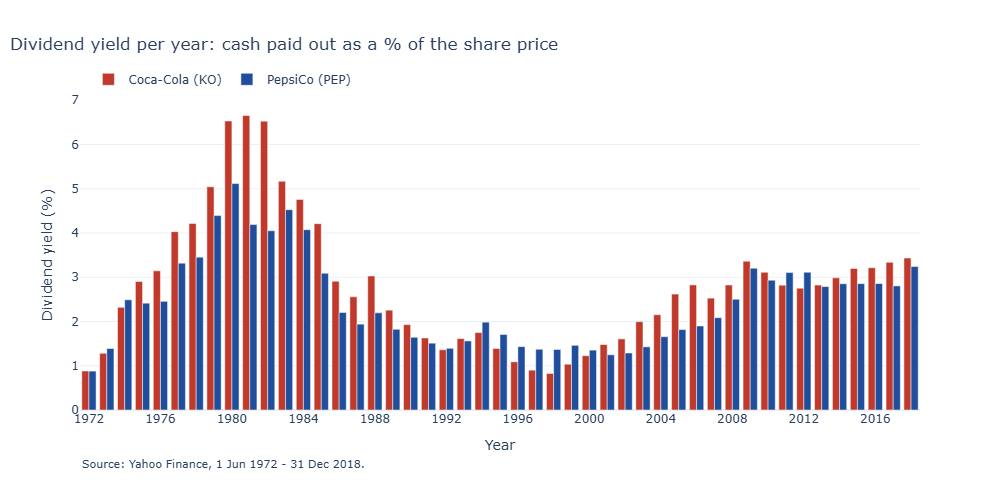

In [6]:
fig = go.Figure()
for ticker in ("KO", "PEP"):
    fig.add_trace(
        go.Bar(
            x=yearly.index,
            y=yearly[(ticker, "yield %")],
            name=NAMES[ticker],
            marker_color=COLORS[ticker],
        )
    )
finish_figure(
    fig,
    "Dividend yield per year: cash paid out as a % of the share price",
    "Year",
    "Dividend yield (%)",
    SOURCE,
)
fig.update_xaxes(dtick=4)
save_figure(fig, "01_dividend_yield", figures_dir)
fig.show()

Four dividends a year for both companies in every full year (three in 1972, counted from June):
187 cash dividends each. The yield is highest in the early 1980s (KO 6.7% in 1981, PEP 5.1% in 1980)
and lowest at the end of the 1990s (KO 0.8% in 1998). A low yield means a high price compared with the
cash the company pays: the "expensive Coca-Cola" of the late 1990s shows up here, and again in the
price ratio of section 5.

### 3.3 How dividends change the prices we use, and a check

On each ex-date the share price drops by about the dividend paid. The adjusted close removes these
drops by scaling down every earlier price, so that it measures the **total** return of holding the
share (price change plus dividends). After 46 years of dividends, the adjusted price of June 1972 is
only about a fifth of the close:

In [7]:
first, last = raw.index[0], raw.index[-1]
levels = pd.DataFrame(
    {
        "Close": [raw.at[d, ("Close", t)] for d in (first, last) for t in ("KO", "PEP")],
        "Adjusted close": [
            raw.at[d, ("Adj Close", t)] for d in (first, last) for t in ("KO", "PEP")
        ],
    },
    index=pd.MultiIndex.from_product(
        [[first.date(), last.date()], ["KO", "PEP"]], names=["Day", "Ticker"]
    ),
)
levels["Adjusted / close"] = levels["Adjusted close"] / levels["Close"]
levels.round(3)

Close  Adjusted close  Adjusted / close
Day        Ticker                                           
1972-06-01 KO        1.378           0.286             0.207
           PEP       1.602           0.367             0.229
2018-12-31 KO       47.350          37.452             0.791
           PEP     110.480          86.719             0.785

**Check: are Yahoo's adjusted prices explained by the dividends Yahoo reports, and by nothing
else?** We rebuild the adjustment ourselves from Yahoo's list (each price before an ex-date is
multiplied by `1 - dividend / previous close`) and compare it with Yahoo's ratio adjusted / close over
the whole 46 years. The largest difference on any day:

In [8]:
rebuild_error = {}
for ticker in ("KO", "PEP"):
    paid = reported.loc[reported["ticker"] == ticker, "dividend"]
    ours = adjustment_from_dividends(close[ticker], paid)
    yahoo = raw[("Adj Close", ticker)] / close[ticker]
    yahoo = yahoo / yahoo.iloc[-1]  # same reference as ours: factor 1 on the last day
    rebuild_error[ticker] = float((ours / yahoo - 1).abs().max())
pd.Series(rebuild_error, name="largest difference (%)").mul(100).round(4).to_frame()

,largest difference (%)
KO,0.0034
PEP,0.0001


The differences are a few thousandths of a percent (prices rounded to the cent), so **the adjusted
prices contain the reported dividends and nothing else**. This proves consistency, not correctness: a
wrong record would be inside the adjusted prices too, and this check could not see it.

### 3.4 Two special records

Dividends are quarterly, about 90 days apart. Searching for two dividends of the same stock less than
40 days apart finds exactly two cases in 46 years:

In [9]:
close_pairs = []
for ticker in ("KO", "PEP"):
    dates = reported.index[reported["ticker"] == ticker]
    for prev, nxt in pairwise(dates):
        if (nxt - prev).days < 40:
            close_pairs.append((ticker, prev.date(), nxt.date(), (nxt - prev).days))
pd.DataFrame(close_pairs, columns=["ticker", "first record", "second record", "days apart"])

,ticker,first record,second record,days apart
0,KO,2001-09-10,2001-09-17,7
1,PEP,1997-09-17,1997-10-07,20


In [10]:
display(
    reported.loc["2001-06-01":"2001-12-31"].query("ticker == 'KO'"),
    reported.loc["1997-07-01":"1997-12-31"].query("ticker == 'PEP'"),
)

,ticker,dividend,split
date,,,
2001-06-13,KO,0.09,0.0
2001-09-10,KO,0.18,0.0
2001-09-17,KO,0.09,0.0
2001-11-28,KO,0.09,0.0


,ticker,dividend,split
date,,,
1997-09-17,PEP,0.125,0.0
1997-10-07,PEP,3.200,0.0
1997-12-10,PEP,0.125,0.0


**KO, September 2001: an error in Yahoo's data.** KO paid 0.09 dollars per quarter that year
(split-adjusted), and the September ex-date moved to the 17th because the exchange was closed from the
11th to the 14th. The 0.18 record of 10 September is a duplicate of the same dividend at its amount
before the 2012 split (0.09 x 2), i.e. a split-handling error. Yahoo applied it to the adjusted prices,
which creates a fake gain on 10 September 2001:

In [11]:
error_day = pd.Timestamp("2001-09-10")
prices = correct_dividend_errors(raw["Adj Close"][["KO", "PEP"]], raw, KNOWN_DIVIDEND_ERRORS)
corrected_days = int((prices["KO"] / raw[("Adj Close", "KO")] - 1).abs().gt(1e-9).sum())
fake_gain = pd.Series(
    {
        "Close (price only, no dividend that day)": raw[("Close", "KO")]
        .pct_change()
        .loc[error_day],
        "Yahoo adjusted close (with the wrong dividend)": raw[("Adj Close", "KO")]
        .pct_change()
        .loc[error_day],
        "Our adjusted close (corrected)": prices["KO"].pct_change().loc[error_day],
    }
)
fake_gain.mul(100).round(2).to_frame("KO return on 2001-09-10 (%)")

12:13:50 INFO     Removed wrong KO dividend of 2001-09-10 00:00:00 (factor 0.99276)

,KO return on 2001-09-10 (%)
"Close (price only, no dividend that day)",0.44
Yahoo adjusted close (with the wrong dividend),1.17
Our adjusted close (corrected),0.44


**Correction** (`correct_dividend_errors` in `src/pairs/data.py`): the adjusted KO prices before
10 September 2001 are divided back by the factor Yahoo applied, so they rise by 0.73% (all 7,395 KO
days from June 1972); PepsiCo is untouched and the raw downloads are kept exactly as Yahoo sent them.
After the correction the return of that day equals the price return, as it must, and our adjusted
prices match the dividends actually paid (the spin-off below included):

In [12]:
corrected_error = {}
adjusting = reported.loc[[key not in wrong for key in keys]]  # everything but the wrong record
for ticker in ("KO", "PEP"):
    paid = adjusting.loc[adjusting["ticker"] == ticker, "dividend"]
    ours = adjustment_from_dividends(close[ticker], paid)
    used = prices[ticker] / close[ticker]
    corrected_error[ticker] = float((ours / (used / used.iloc[-1]) - 1).abs().max())
pd.Series(corrected_error, name="largest difference (%)").mul(100).round(4).to_frame()

,largest difference (%)
KO,0.0034
PEP,0.0001


**PEP, October 1997: a spin-off recorded as a dividend.** On 6 October 1997 PepsiCo separated its
restaurants (Pizza Hut, KFC, Taco Bell) into Tricon Global Restaurants, today Yum! Brands, giving one
Tricon share for every ten PepsiCo shares. Yahoo records this as a "dividend" of 3.20 dollars per
PepsiCo share on 7 October. Treating a spin-off as a cash distribution is the standard way to adjust
prices for it, and the amount is plausible: Tricon traded at about 31 dollars in its first days, i.e.
about 3.1 dollars per PepsiCo share (not verified to the cent). **Kept**, and it is one of the reasons
why PepsiCo before 1997 is a different company (section 7).

## 4. Data cleaning: what was checked, what was removed

Each check below runs on the whole 1972â€“2018 period.

In [13]:
adj = raw["Adj Close"][["KO", "PEP"]]
days_per_year = adj.groupby(adj.index.year).size()
checks = pd.DataFrame(
    [
        ("Missing values (any column)", int(raw.isna().sum().sum())),
        ("Duplicate dates", int(raw.index.duplicated().sum())),
        ("Prices <= 0", int((adj <= 0).sum().sum())),
        ("Days with one stock missing (removed)", int(adj.isna().any(axis=1).sum())),
        ("Trading days per full year, 1973-2018 (min)", int(days_per_year.loc[1973:].min())),
        ("Trading days per full year, 1973-2018 (max)", int(days_per_year.loc[1973:].max())),
        ("Trading days in 1972 (from 1 June)", int(days_per_year.loc[1972])),
    ],
    columns=["Check", "Result"],
).set_index("Check")
checks

,Result
Check,
Missing values (any column),0
Duplicate dates,0
Prices <= 0,0
Days with one stock missing (removed),0
"Trading days per full year, 1973-2018 (min)",248
"Trading days per full year, 1973-2018 (max)",254
Trading days in 1972 (from 1 June),146


**Nothing had to be removed.** A US year has about 252 trading days, so 248â€“254 per full year means
no stretch of data is missing. The longest pauses between two trading days (a normal weekend is 3
days, a long weekend 4) are real closures of the New York Stock Exchange; every other pause in 46
years is at most 4 days.

In [14]:
gaps = longest_gaps(pd.DatetimeIndex(adj.index), 4)
gaps["Reason"] = [
    "Exchange closed 11-14 Sep after the September 11 attacks",
    "New Year's Day, then national day of mourning for President Ford (2 Jan)",
    "Exchange closed 29-30 Oct for Hurricane Sandy",
    "Long weekend (the first of many 4-day pauses)",
]
gaps

,from,to,calendar_days,Reason
0,2001-09-10,2001-09-17,7,Exchange closed 11-14 Sep after the September ...
1,2006-12-29,2007-01-03,5,"New Year's Day, then national day of mourning ..."
2,2012-10-26,2012-10-31,5,Exchange closed 29-30 Oct for Hurricane Sandy
3,1972-09-01,1972-09-05,4,Long weekend (the first of many 4-day pauses)


**Extreme days.** The ten largest one-day moves, with two pieces of evidence. A data error usually
jumps and comes straight back the next day, on ordinary volume. A real event keeps most of the move and
is traded on unusually high volume (`volume_vs_median` = volume that day divided by the stock's typical
daily volume).

In [15]:
moves = largest_moves(close, volume, 10)
moves.round(3)

,date,ticker,return,next_day_return,volume_vs_median
0,1987-10-19,KO,-0.247,0.197,4.933
1,1987-10-20,KO,0.197,0.130,7.183
2,1998-09-01,PEP,0.161,-0.041,2.037
3,2002-10-08,PEP,0.149,0.012,6.410
4,1982-12-14,PEP,-0.143,-0.025,12.748
5,2008-10-13,KO,0.139,-0.075,5.698
6,1987-10-21,KO,0.130,-0.018,4.639
7,2008-10-14,PEP,-0.119,-0.058,9.655
8,1998-08-31,PEP,-0.112,0.161,1.884
9,1974-11-18,KO,-0.111,0.028,1.216


- **19â€“21 October 1987, KO -24.7%, +19.7%, +13.0%**: the "Black Monday" crash and the rebound, on
  5â€“7 times the normal volume. Real.
- **October 2008, KO +13.9% and PEP -11.9%**, and **October 2002, PEP +14.9%**: the 2008 financial
  crisis and a company event, on 6â€“10 times the normal volume. Real.
- **14 December 1982, PEP -14.3%**: 13 times the normal volume and the level is kept. Real (its cause is
  not investigated here).
- **18 November 1974, KO -11.1%**: ordinary volume, but the level is kept the next day. Kept.
- **31 August â€“ 1 September 1998, PEP -11.2% then +16.1%**: a market-wide crash and rebound, but the
  rebound is larger than the fall and the volume only about twice the normal: **we cannot rule out a
  data problem**. Not corrected, only declared: it lies before 2000, so no estimate of the project uses
  it.

All ten are kept: removing real extreme days would make the strategy look safer than it is.

## 5. The three charts of the brief

### 5.1 The two prices together

Both prices start at **100** on 1 June 1972, so the chart shows how each stock grew (dividends
included), whatever its price level. In 46 years KO grows about 130 times and PEP about 236 times: on
an ordinary axis the first 25 years would be a flat line, so the vertical axis is **logarithmic** (the
same vertical distance means the same percentage change).

**How to read it:** if the two lines climb and fall at the same moments, the two stocks react to the
same news. Periods in which one line rises faster than the other are periods in which one company
outgrows the other.

12:13:54 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_prices_log.png

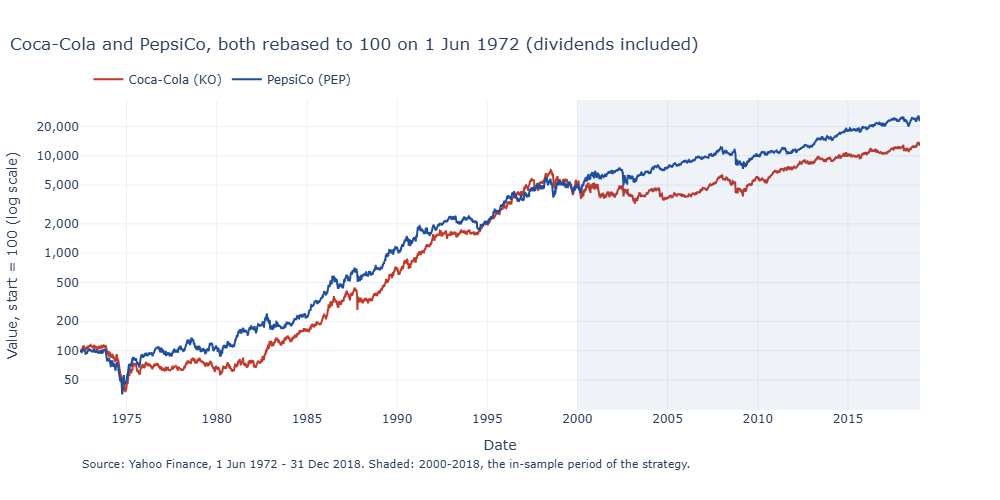

,growth 1972-2018 (x)
Ticker,
KO,130.2
PEP,236.4


In [16]:
rebased = 100 * prices / prices.iloc[0]  # prices = corrected adjusted close (section 3.4)
growth = prices.iloc[-1] / prices.iloc[0]

fig = go.Figure()
fig.add_vrect(x0=PAIR.start, x1=PAIR.in_sample_end, fillcolor="#1f4e9c", opacity=0.07, line_width=0)
for ticker in ("KO", "PEP"):
    fig.add_trace(
        go.Scatter(
            x=rebased.index, y=rebased[ticker], name=NAMES[ticker], line={"color": COLORS[ticker]}
        )
    )
finish_figure(
    fig,
    "Coca-Cola and PepsiCo, both rebased to 100 on 1 Jun 1972 (dividends included)",
    "Date",
    "Value, start = 100 (log scale)",
    SOURCE + SHADED,
)
TICKS = [50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]
fig.update_yaxes(type="log", tickvals=TICKS, ticktext=[f"{v:,}" for v in TICKS])
save_figure(fig, "01_prices_log", figures_dir)
fig.show()
growth.round(1).to_frame("growth 1972-2018 (x)")

### 5.2 The ratio between the two prices

The brief asks for the **ratio or the difference** of the two prices. We use the **ratio** KO / PEP: it
is a pure number, while the difference in dollars grows simply because both prices grow 100â€“200 times.
Its *level* depends on the dividend adjustment; what matters is how it *moves*. The dotted lines mark
the corporate events that changed the two companies.

**How to read it:** a ratio that wanders up and down around a level means a stable relationship, the
situation pairs trading needs. A ratio that trends in one direction for years means one company is
persistently outgrowing the other.

12:14:02 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_price_ratio.png

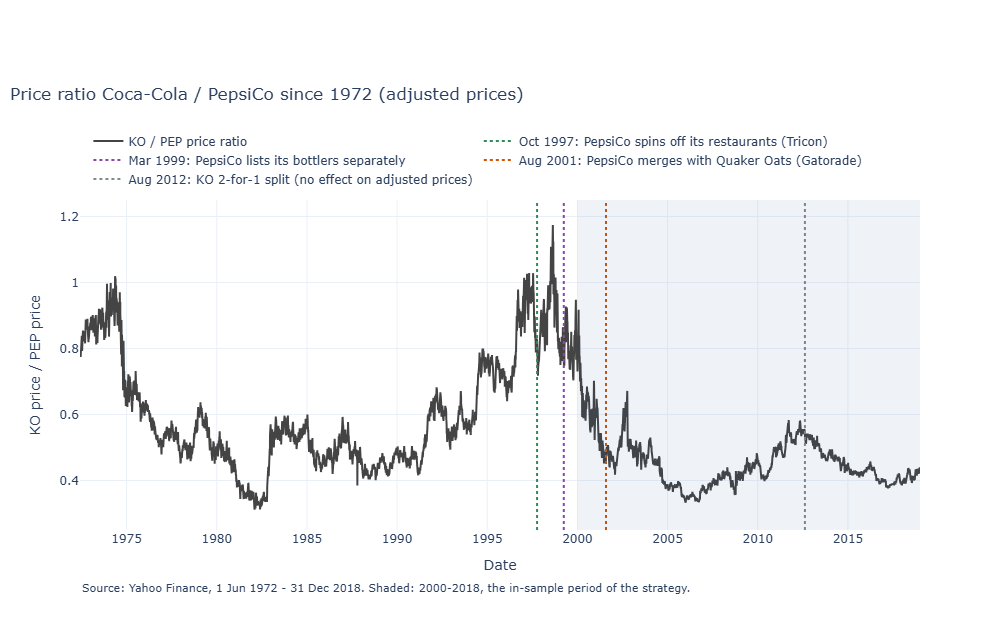

In [17]:
ratio = prices["KO"] / prices["PEP"]
EVENTS = [
    ("1997-10-06", "Oct 1997: PepsiCo spins off its restaurants (Tricon)", "#2e8b57"),
    ("1999-03-31", "Mar 1999: PepsiCo lists its bottlers separately", "#8e44ad"),
    ("2001-08-02", "Aug 2001: PepsiCo merges with Quaker Oats (Gatorade)", "#d35400"),
    ("2012-08-13", "Aug 2012: KO 2-for-1 split (no effect on adjusted prices)", "#7f8c8d"),
]

fig = go.Figure()
fig.add_vrect(x0=PAIR.start, x1=PAIR.in_sample_end, fillcolor="#1f4e9c", opacity=0.07, line_width=0)
fig.add_trace(
    go.Scatter(x=ratio.index, y=ratio, name="KO / PEP price ratio", line={"color": "#444444"})
)
for day, label, color in EVENTS:
    fig.add_trace(
        go.Scatter(
            x=[pd.Timestamp(day)] * 2,
            y=[0.25, 1.25],
            name=label,
            mode="lines",
            line={"color": color, "dash": "dot", "width": 2},
        )
    )
finish_figure(
    fig,
    "Price ratio Coca-Cola / PepsiCo since 1972 (adjusted prices)",
    "Date",
    "KO price / PEP price",
    SOURCE + SHADED,
)
fig.update_yaxes(range=[0.25, 1.25])
fig.update_layout(height=620, margin={"t": 200})  # room for the event legend above the plot
save_figure(fig, "01_price_ratio", figures_dir)
fig.show()

### 5.3 Do the daily moves agree?

The two charts above are about long-term levels. Here we look at day-to-day moves: on a day when
Coca-Cola goes up, does PepsiCo tend to go up too? The **correlation of daily returns**, computed
**separately for each calendar year** (about 250 trading days each), shows whether that link stays
the same over time.

**How to read it:** each bar is one year, the dashed line is the value over the whole 46 years. Bars
of similar height mean a stable link; a much shorter bar is a year in which the two stocks went more
their own way.

12:14:09 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_yearly_correlation.png

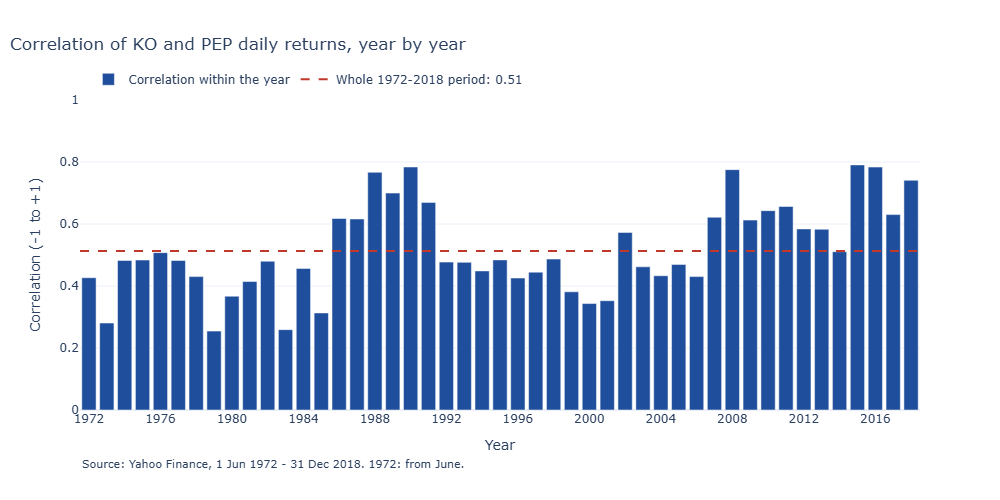

In [18]:
returns = daily_returns(prices)
overall = returns["KO"].corr(returns["PEP"])
by_year = yearly_correlation(returns, "KO", "PEP")

fig = go.Figure()
fig.add_trace(
    go.Bar(x=by_year.index, y=by_year, name="Correlation within the year", marker_color="#1f4e9c")
)
fig.add_trace(
    go.Scatter(
        x=[by_year.index[0] - 0.5, by_year.index[-1] + 0.5],
        y=[overall] * 2,
        name=f"Whole 1972-2018 period: {overall:.2f}",
        mode="lines",
        line={"color": "#c0392b", "dash": "dash"},
    )
)
finish_figure(
    fig,
    "Correlation of KO and PEP daily returns, year by year",
    "Year",
    "Correlation (-1 to +1)",
    SOURCE + " 1972: from June.",
)
fig.update_yaxes(range=[0, 1])
fig.update_xaxes(dtick=4)
save_figure(fig, "01_yearly_correlation", figures_dir)
fig.show()

## 6. Reading the history decade by decade

The same numbers, one row per decade: the correlation of daily returns, how many times each stock grew
(dividends included), and where the price ratio started, ended, and how low and high it went.

In [19]:
DECADES = [
    ("1972-06", "1979", "1970s (from June 1972)"),
    ("1980", "1989", "1980s"),
    ("1990", "1999", "1990s"),
    ("2000", "2009", "2000s"),
    ("2010", "2018", "2010s (to 2018)"),
]
decade_rows = []
for first_year, last_year, label in DECADES:
    p, r, q = (
        prices.loc[first_year:last_year],
        returns.loc[first_year:last_year],
        ratio.loc[first_year:last_year],
    )
    decade_rows.append(
        {
            "decade": label,
            "correlation": r["KO"].corr(r["PEP"]),
            "KO growth (x)": p["KO"].iloc[-1] / p["KO"].iloc[0],
            "PEP growth (x)": p["PEP"].iloc[-1] / p["PEP"].iloc[0],
            "ratio at start": q.iloc[0],
            "ratio at end": q.iloc[-1],
            "ratio low": q.min(),
            "ratio high": q.max(),
        }
    )
decades = pd.DataFrame(decade_rows).set_index("decade")
decades.round(2)

,correlation,KO growth (x),PEP growth (x),ratio at start,ratio at end,ratio low,ratio high
decade,,,,,,,
1970s (from June 1972),0.45,0.67,1.07,0.78,0.49,0.45,1.02
1980s,0.53,10.76,10.92,0.49,0.48,0.31,0.60
1990s,0.51,6.83,4.17,0.48,0.79,0.42,1.17
2000s,0.51,1.27,1.99,0.73,0.47,0.33,0.92
2010s (to 2018),0.66,2.19,2.35,0.46,0.43,0.38,0.58


- **1970s (from June 1972).** Coca-Cola loses a third of its value, dividends included (x0.67), while
  PepsiCo is about flat (x1.07), through the 1973â€“74 bear market and the inflation of the decade. The
  ratio first rises to 1.02 (May 1974), then falls to 0.49. The daily link is the weakest of the five
  decades (correlation 0.45; 0.25 in 1979, the lowest year).
- **1980s.** Both stocks grow about 11 times. The ratio touches its lowest point in 46 years, 0.31 in
  February 1982, and recovers to about 0.5. The daily link strengthens in the second half (0.6â€“0.8 from
  1986 to 1990, including the 1987 crash).
- **1990s.** Coca-Cola grows much faster (x6.8 against x4.2): the ratio climbs from 0.48 to its highest
  point, 1.17 in August 1998, when KO's dividend yield is at its lowest (0.8%). At the end of the decade
  PepsiCo changes shape: restaurants spun off (October 1997), bottlers listed separately (March 1999).
- **2000s.** The gap of the 1990s closes: KO x1.3, PEP x2.0, the ratio falls from 0.73 to 0.33
  (December 2005), then stays around 0.4â€“0.47. PepsiCo merges with Quaker Oats (2001). The daily link
  rises from 0.34 (2000) to 0.78 in the 2008 crisis.
- **2010s (to 2018).** The calmest decade: similar growth (x2.2 and x2.4), the ratio between 0.38 and
  0.58, and the strongest daily link (correlation 0.66).

**In one sentence:** the two stocks are always linked day to day, but their relative level moves in
long swings of 8 to 16 years (highs in 1974 and 1998, lows in 1982 and 2005), and only from about 2005
does the ratio stay in a narrow band.

## 7. Why the strategy is estimated on 2000â€“2018 only

The history above is 46 years long, but the strategy of the next phases is estimated and tuned on
2000â€“2018 only, for three reasons that can be checked:

1. **PepsiCo only became comparable to Coca-Cola at the end of the 1990s.** Until 1997 it also owned
   Pizza Hut, KFC and Taco Bell, spun off as Tricon Global Restaurants effective 6 Oct 1997
   ([SEC filing](https://www.sec.gov/Archives/edgar/data/0001041061/000104106198000004/0001041061-98-000004.txt));
   its bottling arm was listed separately as Pepsi Bottling Group on 31 Mar 1999
   ([SEC filing](https://www.sec.gov/Archives/edgar/data/0001076405/000107640599000017/0001076405-99-000017.txt)).
   From 2000 both are beverage and snack brand companies. One large change stays inside the sample:
   the merger with Quaker Oats (owner of Gatorade) on 2 Aug 2001
   ([CNN](https://money.cnn.com/2001/08/02/deals/pepsico/)). Phase 3 of the brief names exactly this
   kind of change (a merger, a change in a company's business) as what breaks a relationship.
2. **Trading worked differently before 2001.** US stocks were quoted in fractions of a dollar (1/8,
   1/16) until the New York Stock Exchange switched to cents on 29 Jan 2001 (Nasdaq on 9 Apr 2001)
   ([The Daily Record](https://thedailyrecord.com/2001/01/29/nyse-goes-totally-decimal-8212-finally/)),
   so trading costs were much higher and not comparable with today's.
3. **The spread of Phase 2 comes from a regression on price levels.** From 1972 to 2018 the adjusted
   prices grow about 130 times (KO) and 236 times (PEP), against 2.8 and 4.7 times from 2000: one
   regression over 1972â€“2018 would be dominated by the most recent years.

The 2000 start (and the 2018 end of the in-sample) was fixed in the code **before any price was
downloaded** (commit `091e49f`, `feat: fix pair and in-sample split before looking at data`). Having now
seen the data, it **cannot be moved** (for example to 2005, after the drift of 2000â€“2005): that would be
choosing the sample by looking at the results. 19 years of in-sample data is in line with what the brief
asks for any pair (at least 15â€“20 years).

## 8. What we learn

**About the data**

- 11,749 trading days (1 June 1972 â€“ 31 December 2018), nothing missing, nothing removed; the longest
  pauses are real closures of the exchange and the extreme days are real market events, with one
  possible data problem (PepsiCo, 31 Aug â€“ 1 Sep 1998) declared and left in the pre-2000 history.
- Ten stock splits (six KO, four PEP), all correctly handled by Yahoo; 187 quarterly cash dividends
  per company. **One error in Yahoo's data, found and corrected**: a KO dividend of 10 Sep 2001 that
  was never paid. It was found by listing dividends one by one, not by the consistency check, which
  could not see it. One special record kept: PepsiCo's 1997 restaurant spin-off, recorded as a 3.20
  dollar dividend.

**About the relationship**

- **The two stocks are always linked day to day**: correlation of daily returns 0.51 over 46 years,
  between 0.25 (1979) and 0.79 (2015) in single years, and strongest after 2007.
- **Their relative level is not stable over the decades**: the price ratio moves in long swings of 8 to
  16 years, between 0.31 (1982) and 1.17 (1998). Since about 2005 it has stayed in a narrow band
  (0.33â€“0.58) and crossed back and forth, which is the behaviour pairs trading needs.
- **Consequence for the next phases.** A spread can revert within weeks or months while the
  relationship drifts over years. The in-sample 2000â€“2018 starts with one of these drifts (the ratio
  falls from 0.73 to 0.33 by 2005), so a hedge ratio estimated once on it will be pulled by that drift:
  in Phase 2 the spread is *checked, not assumed*, and Phase 3 tests the stability of the relationship
  over time.

**What I am unsure about**

- I did not investigate *why* the ratio swings. A commonly cited reason for KO's 1998 peak is its very
  high valuation at the end of the 1990s: the 0.8% dividend yield of 1998 is consistent with it, but it
  is not a proof.
- The causes of PEP -14.3% (14 Dec 1982) and +14.9% (8 Oct 2002) are not investigated; the Tricon value
  of 3.20 dollars is plausible but not verified to the cent.

## 9. Checks

Every number shown above is verified here: if anything changes (data, code), the notebook stops with
an error instead of silently showing different results. The automated test suite runs this notebook
from top to bottom.

In [20]:
# Period: whole common history, nothing from the out-of-sample, nothing missing or removed
assert raw.index[0] == start == pd.Timestamp("1972-06-01")
for frame in (raw, events, prices):
    assert frame.index.max() <= pd.Timestamp(PAIR.in_sample_end), "out-of-sample data leaked in"
assert len(raw) == 11749 and len(ko_only) == 2599
assert ko_only[("Adj Close", "PEP")].isna().all(), "PEP is quoted before HISTORY_START"
assert checks["Result"].iloc[:4].sum() == 0, "a cleaning check found a problem"
assert len(prices) == len(raw), "rows were dropped"
assert gaps["calendar_days"].tolist() == [7, 5, 5, 4]

# Splits: ten, none leaving a fake jump; prices paid on the day
assert len(splits) == 10 and (splits["ticker"] == "KO").sum() == 6
assert splits["close return that day (%)"].abs().max() < 10  # a missed split: -50% or -67%
assert splits["median volume, 3 months after / before"].max() < 1.5  # a missed split: x2 or x3
assert moves["return"].abs().max() < 0.25  # no unhandled split anywhere (would be <= -50%)
assert real_prices["later splits (x)"].tolist() == [96, 54, 2, 1]
assert abs(real_prices["price paid that day ($)"].iloc[0] - 132.2) < 0.1
assert abs(real_prices["price paid that day ($)"].iloc[1] - 86.5) < 0.1
assert abs(real_prices["price paid that day ($)"].iloc[2] - 56.4) < 0.1  # KO above PEP in 2000
assert abs(real_prices["price paid that day ($)"].iloc[3] - 36.9) < 0.1

# Dividends: every record reported, adjusted prices fully explained, the two special records
assert len(reported) == 376 and len(dividends) == 374
assert (dividends["ticker"] == "KO").sum() == 187 and (dividends["ticker"] == "PEP").sum() == 187
assert (yearly.loc[1973:, ("KO", "number")] == 4).all() and (
    yearly.loc[1973:, ("PEP", "number")] == 4
).all()
assert yearly[("KO", "yield %")].idxmax() == 1981 and yearly[("KO", "yield %")].idxmin() == 1998
assert abs(yearly.at[1998, ("KO", "yield %")] - 0.83) < 0.01
assert yearly[("PEP", "yield %")].idxmax() == 1980
assert [pair[0] for pair in close_pairs] == ["KO", "PEP"]
assert close_pairs[0][1] == error_day.date() and close_pairs[1][2] == SPIN_OFF[0].date()
assert abs(reported.loc[SPIN_OFF[0], "dividend"] - 3.2) < 1e-9
assert max(rebuild_error.values()) < 1e-4, rebuild_error  # Yahoo consistent with its own list
assert max(corrected_error.values()) < 1e-4, corrected_error  # ours consistent with what was paid
assert abs(fake_gain.iloc[2] - fake_gain.iloc[0]) < 1e-4  # fake gain removed
assert fake_gain.iloc[1] - fake_gain.iloc[0] > 0.007  # it was there (+0.73%)
assert corrected_days == 7395
validated = select_until(pd.read_pickle(settings.data_dir / VALIDATED_FILE), PAIR.in_sample_end)
assert (
    prices.loc[pd.Timestamp(PAIR.start) :] - validated
).abs().max().max() < 1e-9  # same as Phase 2 data

# Relationship: expected values, recorded on 10 Oct 2026 from the versioned data checkpoints
assert round(growth["KO"]) == 130 and round(growth["PEP"]) == 236
assert abs(overall - 0.513) < 0.001, overall
assert by_year.index.tolist() == list(range(1972, 2019))
assert by_year.idxmin() == 1979 and by_year.idxmax() == 2015
assert abs(by_year.min() - 0.25) < 0.01 and abs(by_year.max() - 0.79) < 0.01
assert abs(ratio.min() - 0.31) < 0.005 and ratio.idxmin().year == 1982
assert abs(ratio.max() - 1.17) < 0.005 and ratio.idxmax().year == 1998
since_2005 = ratio.loc["2005":]
assert since_2005.min() > 0.325 and since_2005.max() < 0.585, (since_2005.min(), since_2005.max())
assert (
    abs(ratio.loc["2000"].iloc[0] - 0.73) < 0.005 and ratio.loc["2000":"2009"].idxmin().year == 2005
)
expected_decades = {
    "correlation": [0.445, 0.531, 0.507, 0.513, 0.661],
    "KO growth (x)": [0.67, 10.76, 6.83, 1.27, 2.19],
}
for column, values in expected_decades.items():
    assert (decades[column] - values).abs().max() < 0.005, decades[column]
assert abs(decades.at["1970s (from June 1972)", "ratio high"] - 1.02) < 0.005

for name in ("01_prices_log", "01_price_ratio", "01_yearly_correlation", "01_dividend_yield"):
    assert (figures_dir / f"{name}.png").exists(), name

12:14:12 INFO     Kept 4779 of 6733 rows up to 2018-12-31